# World Bank Development Indicators — Data Science Blog Post

**Author:** Christoph  
**Dataset:** World Bank — World Development Indicators (WDI), 2000–2023  
**Process:** CRISP-DM

---

## Business Understanding

We explore global development data to answer five questions relevant to anyone
thinking about where to live, work, or invest:

1. **Which countries have grown richest (GDP per capita) since 2000?**
2. **Where is the relationship between investment and economic growth strongest?**
3. **Which countries offer the best combination of income, life expectancy, and low inequality?**
4. **How did the 2008 financial crisis and COVID-19 (2020) affect employment and growth globally?**
5. **Can we predict a country's life expectancy from economic and social indicators?** *(ML model)*


---
## 1 · Data Understanding

Load the raw CSV, inspect its shape, data types, and missing-value patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
# --- Load raw data ---
RAW_FILE = '../../data/raw/World Development Indicators f057a244-4511-446a-bc9b-11ae16492a3a_Data.csv'

df_raw = pd.read_csv(RAW_FILE, na_values='..', encoding='utf-8-sig')
print(f'Shape: {df_raw.shape}')
df_raw.head(3)

Shape: (6895, 30)


,Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],2006 [YR2006],2007 [YR2007],2008 [YR2008],2009 [YR2009],2010 [YR2010],2011 [YR2011],2012 [YR2012],2013 [YR2013],2014 [YR2014],2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,-9.431974,28.600001,8.832278,1.414118,11.229715,5.357403,13.826320,3.924984,21.390528,14.362441,0.426355,12.752287,5.600745,2.724543,1.451315,2.260314,2.647003,1.189228,3.911603,-2.351101,-20.738839,-6.240172,2.266944,1.873193,NaN
1,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,308.318270,277.118051,338.139974,346.071627,338.637274,363.640141,367.758312,410.757729,417.647283,488.830652,542.871030,525.426983,568.929021,580.603833,575.146246,565.569730,563.872337,562.769574,553.125152,557.861533,527.834554,408.625855,377.665627,378.066303,374.376696,NaN
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,1617.826475,1454.110782,1774.308743,1815.928200,1776.918207,1908.114782,1929.723897,2155.353068,2191.504356,2565.022086,2848.586061,2757.052587,2985.319145,3046.579931,3017.942544,2967.692067,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN


In [3]:
# Column names and data types
df_raw.dtypes

Country Name         str
Country Code         str
Series Name          str
Series Code          str
2000 [YR2000]    float64
2001 [YR2001]    float64
2002 [YR2002]    float64
2003 [YR2003]    float64
2004 [YR2004]    float64
2005 [YR2005]    float64
2006 [YR2006]    float64
2007 [YR2007]    float64
2008 [YR2008]    float64
2009 [YR2009]    float64
2010 [YR2010]    float64
2011 [YR2011]    float64
2012 [YR2012]    float64
2013 [YR2013]    float64
2014 [YR2014]    float64
2015 [YR2015]    float64
2016 [YR2016]    float64
2017 [YR2017]    float64
2018 [YR2018]    float64
2019 [YR2019]    float64
2020 [YR2020]    float64
2021 [YR2021]    float64
2022 [YR2022]    float64
2023 [YR2023]    float64
2024 [YR2024]    float64
2025 [YR2025]    float64
dtype: object

In [4]:
# How many unique countries and indicators?
print('Countries / regions:', df_raw['Country Name'].nunique())
print('Indicators:         ', df_raw['Series Name'].nunique())
print()
print(df_raw['Series Name'].unique())

Countries / regions: 267
Indicators:          26

<StringArray>
[                                                                               'GDP growth (annual %)',
                                                                   'GDP per capita (constant 2015 US$)',
                                                  'GDP per capita, PPP (constant 2021 international $)',
                                                                             'Gross savings (% of GDP)',
                                            'Adjusted net national income per capita (annual % growth)',
                               'Adjusted net savings, including particulate emission damage (% of GNI)',
                                  'Unemployment, total (% of total labor force) (modeled ILO estimate)',
                                'Employment to population ratio, 15+, total (%) (modeled ILO estimate)',
        'Labor force participation rate, total (% of total population ages 15+) (modeled ILO est

In [5]:
# Missing-value summary per indicator (% missing across all country-years)
year_cols = [c for c in df_raw.columns if c.startswith('20')]

missing_pct = (
    df_raw.groupby('Series Name')[year_cols]
    .apply(lambda g: g.isna().mean().mean() * 100)
    .sort_values(ascending=False)
    .rename('% missing')
)
missing_pct.round(1)

Series Name
Domestic credit provided by financial sector (% of GDP)                                                 82.9
Gini index                                                                                              73.0
Gross fixed capital formation, private sector (% of GDP)                                                71.2
Research and development expenditure (% of GDP)                                                         58.2
Lending interest rate (%)                                                                               54.4
Intentional homicides (per 100,000 people)                                                              49.9
Adjusted net national income per capita (annual % growth)                                               45.4
Adjusted net savings, including particulate emission damage (% of GNI)                                  42.0
Gross savings (% of GDP)                                                                                29.4
PPP con

---
## 2 · Data Preparation

Steps:
- Reshape from **wide** (years as columns) → **long** (one row per country-indicator-year)
- Keep only true countries (drop World Bank aggregate regions)
- Limit years to 2000–2023 (drop 2024–2025, which are mostly empty)
- Handle remaining missing values

In [6]:
# --- Reshape: wide → long ---
df_long = df_raw.melt(
    id_vars=['Country Name', 'Country Code', 'Series Name', 'Series Code'],
    value_vars=year_cols,
    var_name='year_label',
    value_name='value'
)

# Extract the 4-digit year from labels like '2005 [YR2005]'
df_long['year'] = df_long['year_label'].str.extract(r'(\d{4})').astype(int)
df_long = df_long.drop(columns='year_label')

# Keep only 2000–2023
df_long = df_long[df_long['year'].between(2000, 2023)]

print(f'Long format shape: {df_long.shape}')
df_long.head()

Long format shape: (165480, 6)


,Country Name,Country Code,Series Name,Series Code,value,year
0,Afghanistan,AFG,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,2000
1,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,308.318270,2000
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,1617.826475,2000
3,Afghanistan,AFG,Gross savings (% of GDP),NY.GNS.ICTR.ZS,NaN,2000
4,Afghanistan,AFG,Adjusted net national income per capita (annua...,NY.ADJ.NNTY.PC.KD.ZG,NaN,2000


In [7]:
# --- Remove World Bank aggregate regions (they have 3-letter codes like 'WLD', 'EAS') ---
# True country ISO-3 codes are a known list; WB aggregates tend to be 2-letter or special
# Simple heuristic: keep rows whose Country Code appears in the WB country list
# We will identify aggregates by checking for known patterns

# World Bank aggregate codes to exclude
AGGREGATE_CODES = {
    'AFE','AFW','ARB','CEB','CSS','EAP','EAR','EAS','ECA','ECS',
    'EMU','EUU','FCS','HIC','HPC','IBD','IBT','IDA','IDB','IDX',
    'LAC','LCN','LDC','LIC','LMC','LMY','LTE','MEA','MIC','MNA',
    'NAC','OED','OSS','PRE','PSS','PST','SAS','SSA','SSF','SST',
    'TEA','TEC','TLA','TMN','TSA','TSS','UMC','WLD','XZN'
}

df_countries = df_long[~df_long['Country Code'].isin(AGGREGATE_CODES)].copy()
print(f'Rows after removing aggregates: {df_countries.shape[0]}')
print(f'True countries remaining: {df_countries["Country Name"].nunique()}')

Rows after removing aggregates: 136152
True countries remaining: 220


In [8]:
# --- Pivot to wide-by-indicator so each row = one country-year ---
df = df_countries.pivot_table(
    index=['Country Name', 'Country Code', 'year'],
    columns='Series Name',
    values='value'
).reset_index()

# Flatten column names
df.columns.name = None
print(f'Analysis-ready shape: {df.shape}')
df.head()

Analysis-ready shape: (5208, 29)


,Country Name,Country Code,year,Adjusted net national income per capita (annual % growth),"Adjusted net savings, including particulate emission damage (% of GNI)",Broad money (% of GDP),Current health expenditure per capita (current US$),Domestic credit provided by financial sector (% of GDP),"Employment to population ratio, 15+, total (%) (modeled ILO estimate)","Foreign direct investment, net inflows (% of GDP)",GDP growth (annual %),GDP per capita (constant 2015 US$),"GDP per capita, PPP (constant 2021 international $)",GDP per person employed (constant 2021 PPP $),Gini index,Gross capital formation (% of GDP),"Gross fixed capital formation, private sector (% of GDP)",Gross savings (% of GDP),Households and NPISHs Final consumption expenditure per capita (constant 2015 US$),"Inflation, consumer prices (annual %)","Intentional homicides (per 100,000 people)","Labor force participation rate, total (% of total population ages 15+) (modeled ILO estimate)",Lending interest rate (%),"Life expectancy at birth, total (years)","PPP conversion factor, households and NPISHs Final consumption expenditure (LCU per international $)",Population growth (annual %),Research and development expenditure (% of GDP),Trade (% of GDP),"Unemployment, total (% of total labor force) (modeled ILO estimate)"
0,Afghanistan,AFG,2000,NaN,NaN,NaN,NaN,NaN,42.885,0.004828,NaN,308.318270,1617.826475,7548.716782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.562,NaN,55.005,NaN,1.212176,NaN,NaN,7.897
1,Afghanistan,AFG,2001,NaN,NaN,NaN,NaN,NaN,42.817,0.024169,-9.431974,277.118051,1454.110782,6815.205362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.526,NaN,55.511,NaN,0.762005,NaN,NaN,7.973
2,Afghanistan,AFG,2002,NaN,NaN,NaN,16.706974,NaN,42.846,1.306950,28.600001,338.139974,1774.308743,8321.856529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.505,NaN,56.225,NaN,5.252030,NaN,NaN,7.867
3,Afghanistan,AFG,2003,NaN,NaN,NaN,17.746025,NaN,42.850,1.278493,8.832278,346.071627,1815.928200,8516.673357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.497,NaN,57.171,NaN,6.145194,NaN,NaN,7.844
4,Afghanistan,AFG,2004,NaN,NaN,NaN,21.423004,NaN,42.881,3.577104,1.414118,338.637274,1776.918207,8317.100255,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.506,NaN,57.810,11.359367,3.575835,NaN,NaN,7.794


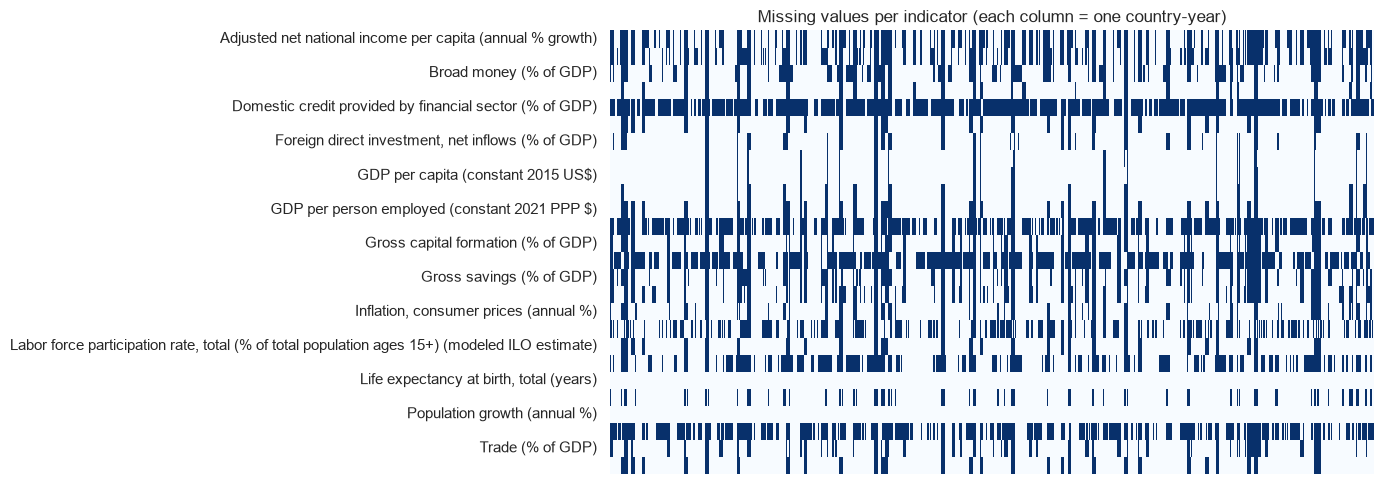

In [9]:
# --- Missing value heatmap ---
missing_matrix = df.drop(columns=['Country Name', 'Country Code', 'year']).isna()

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    missing_matrix.T,
    cbar=False, xticklabels=False, ax=ax,
    cmap='Blues', linewidths=0
)
ax.set_title('Missing values per indicator (each column = one country-year)')
plt.tight_layout()
plt.show()

### Missing Value Strategy

Each question uses a different subset of indicators. Rows are dropped wherever
a required indicator is missing. The table below documents what was removed for
each question and why that is acceptable.

| Question | Indicators used | Approach | Countries / rows kept | Limitation |
|---|---|---|---|---|
| Q1: GDP growth ranking | GDP per capita PPP | Drop country if 2000 or 2022 value is missing | ~170 countries | Countries founded after 2000 (e.g. South Sudan) are excluded |
| Q2: Investment vs growth | Gross capital formation, GDP growth | Drop row if either value is missing | ~3,500 country-years | Sparser countries contribute fewer data points |
| Q3: Livability index | GDP PPP, Life expectancy, Gini index | Use most recent available value per country; drop country if any of the three is entirely absent | 165 of ~210 countries | Gini has 73% missing — countries without a recent household survey are excluded; the three indicator values may come from different years |
| Q4: Crisis chart | GDP growth | Drop row if missing | ~3,200 country-years | A few small economies with no growth data are excluded from the world average |
| Q5: ML model | 8 features + life expectancy | Drop row if any feature or target is missing (complete-case analysis) | ~2,100 country-years | Countries with sparse economic reporting are under-represented |

**Why dropping is acceptable:** All five questions compare countries or compute
global averages — not individual time series where gaps would distort a trend.
Dropping sparse rows removes countries with poor statistical reporting capacity,
which are often lower-income economies. This is a known limitation: results may
overrepresent well-documented countries. Each question notes the actual
country or row count used.


---
## 3 · Analysis — Question 1
### Which countries have grown richest (GDP per capita) since 2000?

Strategy: compare each country's GDP per capita (PPP) in 2000 vs. 2022, compute % change, rank top 20.

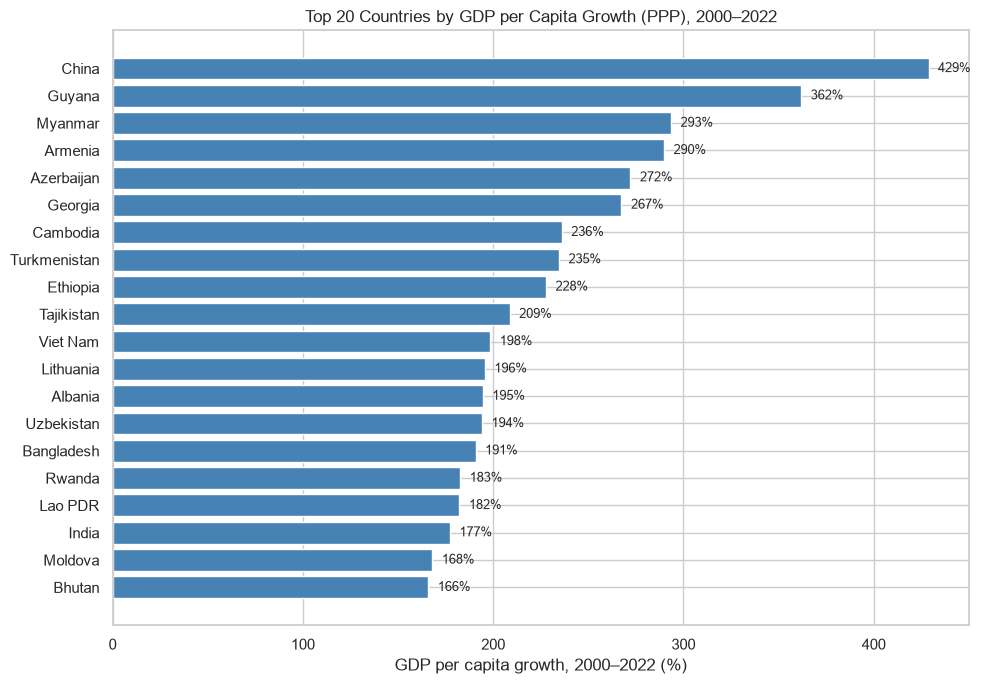

              gdp_2000  gdp_2022  growth_pct
Country Name                                
China           4066.0   21499.0       429.0
Guyana          8025.0   37068.0       362.0
Myanmar         1360.0    5350.0       293.0
Armenia         4589.0   17886.0       290.0
Azerbaijan      5657.0   21051.0       272.0
Georgia         5706.0   20967.0       267.0
Cambodia        1922.0    6458.0       236.0
Turkmenistan    5064.0   16944.0       235.0
Ethiopia         810.0    2656.0       228.0
Tajikistan      1365.0    4214.0       209.0
Viet Nam        4349.0   12980.0       198.0
Lithuania      15777.0   46643.0       196.0
Albania         6582.0   19389.0       195.0
Uzbekistan      3431.0   10091.0       194.0
Bangladesh      2713.0    7888.0       191.0
Rwanda          1055.0    2983.0       183.0
Lao PDR         2899.0    8183.0       182.0
India           3010.0    8347.0       177.0
Moldova         5727.0   15350.0       168.0
Bhutan          5288.0   14061.0       166.0


In [10]:
# --- Q1: Fastest-growing countries by GDP per capita (PPP), 2000–2022 ---
gdp_col = 'GDP per capita, PPP (constant 2021 international $)'

# Keep only rows where GDP data exists
q1 = df[['Country Name', 'year', gdp_col]].dropna(subset=[gdp_col])

# One value per country for 2000 and 2022
gdp_2000 = q1[q1['year'] == 2000].set_index('Country Name')[gdp_col].rename('gdp_2000')
gdp_2022 = q1[q1['year'] == 2022].set_index('Country Name')[gdp_col].rename('gdp_2022')

# Join and compute % growth — drops any country missing either year
q1_compare = pd.concat([gdp_2000, gdp_2022], axis=1).dropna()
q1_compare['growth_pct'] = (q1_compare['gdp_2022'] - q1_compare['gdp_2000']) / q1_compare['gdp_2000'] * 100

# Top 20 fastest-growing
top20 = q1_compare.sort_values('growth_pct', ascending=False).head(20)

# Horizontal bar chart (reversed so #1 is at the top)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20.index[::-1], top20['growth_pct'][::-1], color='steelblue')
ax.set_xlabel('GDP per capita growth, 2000–2022 (%)')
ax.set_title('Top 20 Countries by GDP per Capita Growth (PPP), 2000–2022')

# Add % labels at the end of each bar
for i, (country, row) in enumerate(top20[::-1].iterrows()):
    ax.text(row['growth_pct'] + 5, i, f"{row['growth_pct']:.0f}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Also print the numbers
print(top20[['gdp_2000', 'gdp_2022', 'growth_pct']].round(0).to_string())

---
## 4 · Analysis — Question 2
### Where is the relationship between investment and economic growth strongest?

Strategy: scatter plot of gross capital formation (% GDP) vs. GDP growth, coloured by region or income group.

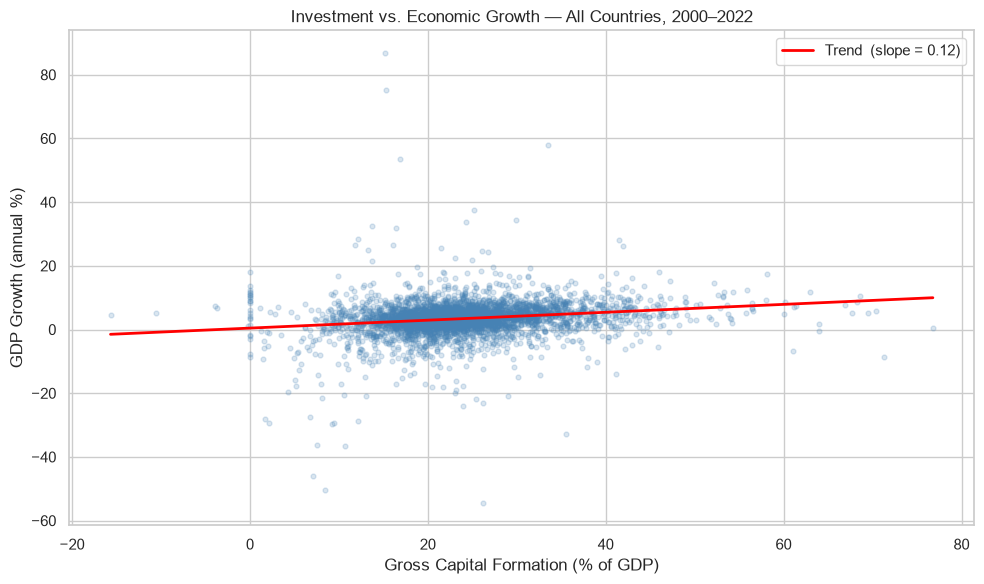

Overall Pearson correlation: 0.189
Data points used: 4,075


In [11]:
# --- Q2: Does higher investment lead to higher growth? ---
invest_col = 'Gross capital formation (% of GDP)'
growth_col = 'GDP growth (annual %)'

# Keep only rows where both values exist
q2 = df[['Country Name', 'year', invest_col, growth_col]].dropna()

# Scatter plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(q2[invest_col], q2[growth_col], alpha=0.2, s=12, color='steelblue')

# Trend line — np.polyfit fits a straight line (degree 1) through all points
slope, intercept = np.polyfit(q2[invest_col], q2[growth_col], 1)
x_line = np.linspace(q2[invest_col].min(), q2[invest_col].max(), 200)
ax.plot(x_line, slope * x_line + intercept, color='red', linewidth=2,
        label=f'Trend  (slope = {slope:.2f})')

ax.set_xlabel('Gross Capital Formation (% of GDP)')
ax.set_ylabel('GDP Growth (annual %)')
ax.set_title('Investment vs. Economic Growth — All Countries, 2000–2022')
ax.legend()
plt.tight_layout()
plt.show()

# Correlation: how strongly do the two variables move together?
# +1 = perfect positive relationship, 0 = none, -1 = opposite
corr = q2[invest_col].corr(q2[growth_col])
print(f'Overall Pearson correlation: {corr:.3f}')
print(f'Data points used: {len(q2):,}')

In [12]:
# Compute correlation per country (only include countries with at least 10 years of data)
country_corr = (
    q2.groupby('Country Name')
    .apply(lambda g: g[invest_col].corr(g[growth_col]) if len(g) >= 10 else np.nan)
    .dropna()
    .sort_values(ascending=False)
    .rename('correlation')
)

print('Top 10 — investment most strongly predicts growth:')
print(country_corr.head(10).round(3).to_string())
print()
print('Bottom 10 — investment least (or inversely) predicts growth:')
print(country_corr.tail(10).round(3).to_string())

Top 10 — investment most strongly predicts growth:
Country Name
Mongolia            0.760
Cote d'Ivoire       0.751
Egypt, Arab Rep.    0.699
Yemen, Rep.         0.698
Zimbabwe            0.694
Uruguay             0.678
Marshall Islands    0.658
Kiribati            0.653
Poland              0.646
Lebanon             0.640

Bottom 10 — investment least (or inversely) predicts growth:
Country Name
Norway                 -0.352
Algeria                -0.355
Tanzania               -0.359
Switzerland            -0.376
United Arab Emirates   -0.382
Cambodia               -0.395
Guinea-Bissau          -0.398
Zambia                 -0.412
Tajikistan             -0.481
Somalia, Fed. Rep.     -0.488


---
## 5 · Analysis — Question 3
### Which countries offer the best combination of income, life expectancy, and low inequality?

Strategy: build a simple composite 'livability index' from GDP per capita (PPP), life expectancy, and (inverted) Gini index; rank top/bottom 20.

In [13]:
# --- Q3: Livability Index ---
gdp_col  = 'GDP per capita, PPP (constant 2021 international $)'
life_col = 'Life expectancy at birth, total (years)'
gini_col = 'Gini index'

def latest_value(dataframe, col):
    """Return the most recent non-null value per country for one indicator."""
    return (
        dataframe[['Country Name', 'year', col]]
        .dropna(subset=[col])
        .sort_values('year', ascending=False)
        .drop_duplicates('Country Name')
        .set_index('Country Name')[col]
    )

q3 = pd.concat([
    latest_value(df, gdp_col).rename('gdp_ppp'),
    latest_value(df, life_col).rename('life_exp'),
    latest_value(df, gini_col).rename('gini'),
], axis=1).dropna()   # keep only countries with all three values

print(f'Countries with all three indicators: {len(q3)}')
print(q3.describe().round(1))

Countries with all three indicators: 165
        gdp_ppp  life_exp   gini
count     165.0     165.0  165.0
mean    23332.4      72.9   36.1
std     24397.2       7.1    7.1
min      1033.0      54.5   23.8
25%      5541.3      67.2   30.9
50%     14321.2      73.6   35.3
75%     34703.2      78.0   40.1
max    130048.9      84.2   59.1


In [14]:
# Q3 missing-value breakdown — how many countries are lost at each step
all_countries = df["Country Name"].nunique()
has_gdp  = df.groupby("Country Name")[gdp_col].apply(lambda s: s.notna().any()).sum()
has_life = df.groupby("Country Name")[life_col].apply(lambda s: s.notna().any()).sum()
has_gini = df.groupby("Country Name")[gini_col].apply(lambda s: s.notna().any()).sum()

print("Q3 — countries available at each filter step:")
print(f"  All countries in dataset:      {all_countries}")
print(f"  Have any GDP PPP data:         {has_gdp}")
print(f"  Have any life expectancy data: {has_life}")
print(f"  Have any Gini index data:      {has_gini}  <- binding constraint (73% missing)")
print(f"  Have all three (used in Q3):   {len(q3)}")
print()
print("Note: values come from each country's most recent available year,")
print("so the three indicator values may be from different years.")


Q3 — countries available at each filter step:
  All countries in dataset:      217
  Have any GDP PPP data:         199
  Have any life expectancy data: 217
  Have any Gini index data:      168  <- binding constraint (73% missing)
  Have all three (used in Q3):   165

Note: values come from each country's most recent available year,
so the three indicator values may be from different years.


In [15]:
def minmax(series):
    """Scale a series to 0–1. Lowest value → 0, highest → 1."""
    return (series - series.min()) / (series.max() - series.min())

q3['gdp_score']  = minmax(q3['gdp_ppp'])
q3['life_score'] = minmax(q3['life_exp'])
q3['gini_score'] = 1 - minmax(q3['gini'])   # invert: less inequality = better score

# Equal-weight average of the three scores
q3['livability_index'] = (q3['gdp_score'] + q3['life_score'] + q3['gini_score']) / 3

top20_q3 = q3.sort_values('livability_index', ascending=False).head(20)
bot20_q3 = q3.sort_values('livability_index').head(20)

print('Top 10:')
print(top20_q3[['gdp_ppp', 'life_exp', 'gini', 'livability_index']].head(10).round(2).to_string())

Top 10:
                        gdp_ppp  life_exp  gini  livability_index
Country Name                                                     
Ireland               117659.73     82.81  29.0              0.90
Luxembourg            130048.92     83.31  33.6              0.90
Norway                 94364.96     83.01  26.5              0.87
Qatar                 116159.14     82.37  35.1              0.84
United Arab Emirates   70239.83     82.91  26.4              0.81
Netherlands            70198.95     81.86  25.7              0.80
Iceland                69268.12     82.46  26.8              0.80
Switzerland            85383.36     84.16  33.8              0.79
Belgium                63042.01     82.40  26.8              0.78
Sweden                 62122.51     83.31  29.3              0.76


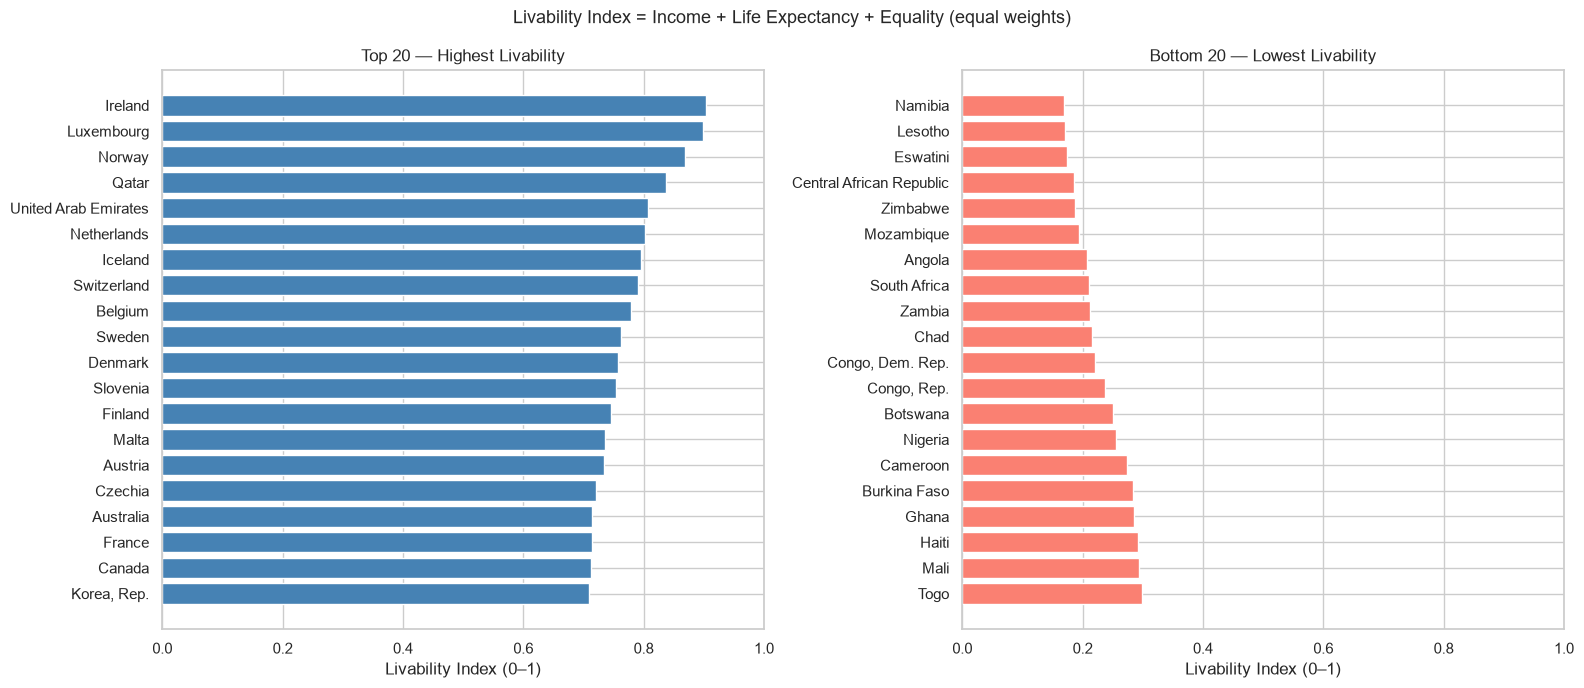

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top 20 (sorted ascending so #1 appears at the top of the chart)
top_plot = top20_q3.sort_values('livability_index')
axes[0].barh(top_plot.index, top_plot['livability_index'], color='steelblue')
axes[0].set_title('Top 20 — Highest Livability')
axes[0].set_xlabel('Livability Index (0–1)')
axes[0].set_xlim(0, 1)

# Bottom 20
bot_plot = bot20_q3.sort_values('livability_index', ascending=False)
axes[1].barh(bot_plot.index, bot_plot['livability_index'], color='salmon')
axes[1].set_title('Bottom 20 — Lowest Livability')
axes[1].set_xlabel('Livability Index (0–1)')
axes[1].set_xlim(0, 1)

plt.suptitle('Livability Index = Income + Life Expectancy + Equality (equal weights)',
             fontsize=13)
plt.tight_layout()
plt.show()

---
## 6 · Analysis — Question 4
### How did the 2008 crisis and COVID-19 (2020) affect employment and growth globally?

Strategy: line plot of world-average GDP growth and unemployment rate from 2000–2023, with crisis years highlighted.

In [17]:
# --- Q4: Global impact of the 2008 crisis and COVID-19 ---
growth_col = 'GDP growth (annual %)'
unemp_col  = 'Unemployment, total (% of total labor force) (modeled ILO estimate)'

# Average across all countries for each year
q4_growth = df.groupby('year')[growth_col].mean().rename('avg_growth')
q4_unemp  = df.groupby('year')[unemp_col].mean().rename('avg_unemp')

q4 = pd.concat([q4_growth, q4_unemp], axis=1).reset_index()

# Print key crisis years so we can see the numbers
crisis_years = [2007, 2008, 2009, 2019, 2020, 2021]
print('Key years:')
print(q4[q4['year'].isin(crisis_years)][['year', 'avg_growth', 'avg_unemp']].round(2).to_string(index=False))

Key years:
 year  avg_growth  avg_unemp
 2007        5.47       7.52
 2008        3.73       7.43
 2009       -0.28       8.22
 2019        2.76       7.28
 2020       -5.28       8.36
 2021        5.73       8.07


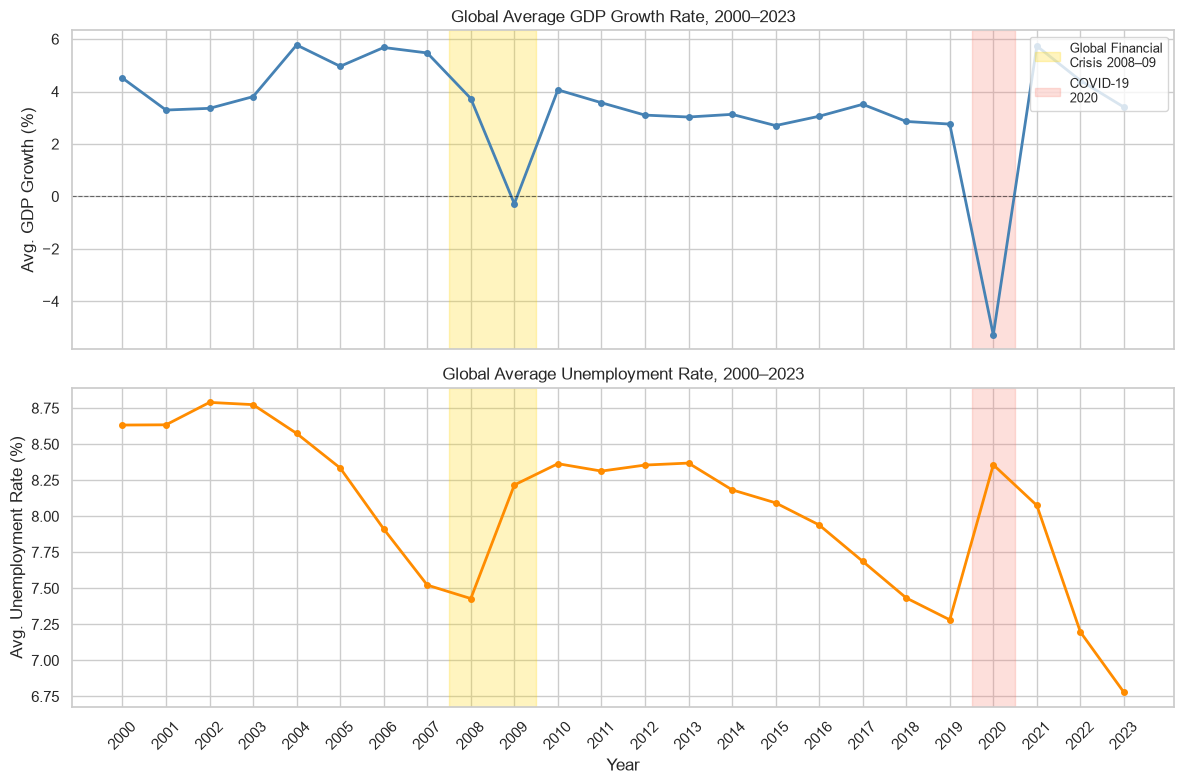

In [18]:
# Crisis periods: (start_year, end_year, label, shade_color)
crises = [
    (2008, 2009, 'Global Financial\nCrisis 2008–09', 'gold'),
    (2020, 2020, 'COVID-19\n2020',                   'salmon'),
]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# --- Top panel: GDP growth ---
ax1.plot(q4['year'], q4['avg_growth'], color='steelblue',
         linewidth=2, marker='o', markersize=4)
ax1.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
ax1.set_ylabel('Avg. GDP Growth (%)')
ax1.set_title('Global Average GDP Growth Rate, 2000–2023')

# --- Bottom panel: Unemployment ---
ax2.plot(q4['year'], q4['avg_unemp'], color='darkorange',
         linewidth=2, marker='o', markersize=4)
ax2.set_ylabel('Avg. Unemployment Rate (%)')
ax2.set_title('Global Average Unemployment Rate, 2000–2023')
ax2.set_xlabel('Year')

# Shade crisis bands on both panels
for ax in [ax1, ax2]:
    for start, end, label, color in crises:
        ax.axvspan(start - 0.5, end + 0.5, alpha=0.25, color=color, label=label)
    ax.set_xticks(q4['year'])
    ax.tick_params(axis='x', rotation=45)

# One legend on the top panel
handles, labels = ax1.get_legend_handles_labels()
ax1.legend(handles, labels, loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

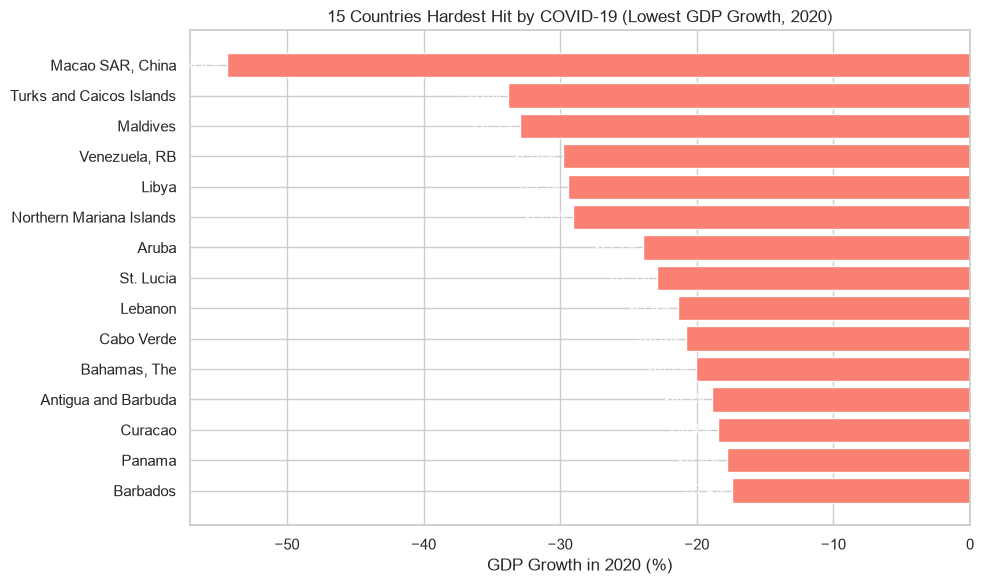

In [19]:
# Rank countries by GDP growth in 2020 (most negative = hardest hit)
covid_hit = (
    df[df['year'] == 2020][['Country Name', growth_col]]
    .dropna()
    .sort_values(growth_col)
    .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(covid_hit['Country Name'][::-1], covid_hit[growth_col][::-1], color='salmon')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('GDP Growth in 2020 (%)')
ax.set_title('15 Countries Hardest Hit by COVID-19 (Lowest GDP Growth, 2020)')

# Label each bar with its value
for bar, val in zip(bars, covid_hit[growth_col][::-1]):
    ax.text(val - 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', ha='right', fontsize=9, color='white')

plt.tight_layout()
plt.show()

---
## 7 · Modeling — Question 5
### Can we predict a country's life expectancy from economic and social indicators?

Strategy:
- Features: GDP per capita (PPP), health expenditure per capita, inflation, unemployment, gross savings, trade
- Target: life expectancy at birth
- Model: Linear Regression (baseline) → Random Forest Regressor
- Evaluation: R², MAE, cross-validation

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

# --- Q5: Predict life expectancy from economic indicators ---
target = 'Life expectancy at birth, total (years)'

features = [
    'GDP per capita, PPP (constant 2021 international $)',
    'Current health expenditure per capita (current US$)',
    'Inflation, consumer prices (annual %)',
    'Unemployment, total (% of total labor force) (modeled ILO estimate)',
    'Trade (% of GDP)',
    'Foreign direct investment, net inflows (% of GDP)',
    'Population growth (annual %)',
    'Gross capital formation (% of GDP)',
]

# Short names for charts
feature_labels = [
    'GDP per capita PPP',
    'Health expenditure/capita',
    'Inflation',
    'Unemployment',
    'Trade (% GDP)',
    'FDI net inflows',
    'Population growth',
    'Capital formation',
]

# Drop any row missing a feature or the target
q5 = df[['Country Name', 'year'] + features + [target]].dropna()
print(f'Rows available for modelling: {len(q5):,}')
print(f'Countries represented:        {q5["Country Name"].nunique()}')

Rows available for modelling: 3,495
Countries represented:        161


In [21]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score

X = q5[features].values
y = q5[target].values

# 80% for training, 20% held back for testing
# random_state=42 makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Training rows: {len(X_train):,}   Test rows: {len(X_test):,}')

# Pipeline = StandardScaler then model
# StandardScaler shifts every feature to mean=0, std=1
# Without this, GDP (in thousands) would dwarf inflation (in %) and distort the model
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LinearRegression())
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)

lr_r2  = r2_score(y_test, y_pred_lr)
lr_mae = mean_absolute_error(y_test, y_pred_lr)
print(f'\nLinear Regression baseline:')
print(f'  R²  = {lr_r2:.3f}   (0 = no better than guessing the mean, 1 = perfect)')
print(f'  MAE = {lr_mae:.2f} years  (average error in the prediction)')

Training rows: 2,796   Test rows: 699

Linear Regression baseline:
  R²  = 0.600   (0 = no better than guessing the mean, 1 = perfect)
  MAE = 4.09 years  (average error in the prediction)


In [22]:
# Random Forest does not need scaling — it splits data by thresholds, not distance
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_r2  = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
print(f'Random Forest:')
print(f'  R²  = {rf_r2:.3f}')
print(f'  MAE = {rf_mae:.2f} years')

# Cross-validation: split data into 5 folds, train+test 5 times, average the score
# More reliable than a single train/test split because it uses all data for testing
cv_scores = cross_val_score(rf, X, y, cv=5, scoring='r2')
print(f'\n5-fold cross-validation R²: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}')
print('(mean ± standard deviation across the 5 folds)')

Random Forest:
  R²  = 0.922
  MAE = 1.46 years

5-fold cross-validation R²: 0.725 ± 0.059
(mean ± standard deviation across the 5 folds)


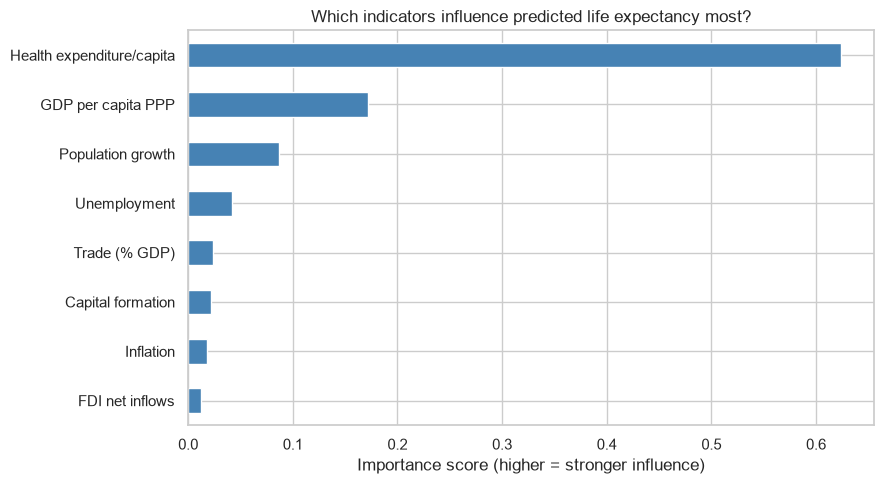

In [23]:
importances = pd.Series(rf.feature_importances_, index=feature_labels).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot.barh(ax=ax, color='steelblue')
ax.set_title('Which indicators influence predicted life expectancy most?')
ax.set_xlabel('Importance score (higher = stronger influence)')
plt.tight_layout()
plt.show()

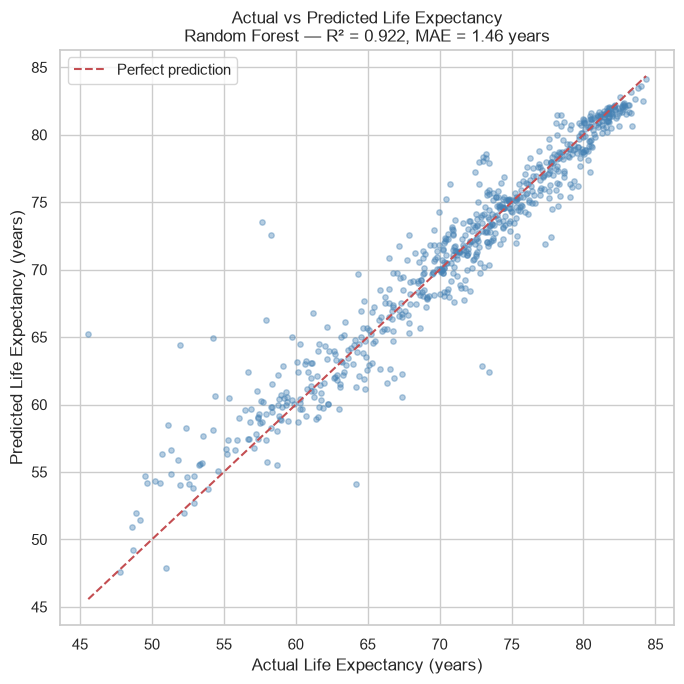

In [24]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_pred_rf, alpha=0.4, s=15, color='steelblue')

# Perfect prediction line: if model were flawless, all dots would sit on this line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'r--', linewidth=1.5, label='Perfect prediction')

ax.set_xlabel('Actual Life Expectancy (years)')
ax.set_ylabel('Predicted Life Expectancy (years)')
ax.set_title(f'Actual vs Predicted Life Expectancy\nRandom Forest — R² = {rf_r2:.3f}, MAE = {rf_mae:.2f} years')
ax.legend()
plt.tight_layout()
plt.show()

---
## 8 · Prediction Scenario

Imagine a hypothetical country with the following profile and ask the model to predict its life expectancy:

| Indicator | Value |
|---|---|
| GDP per capita PPP | 25,000 |
| Health expenditure per capita | 800 |
| Inflation | 3% |
| Unemployment | 6% |
| Gross savings | 20% of GDP |
| Trade | 60% of GDP |

In [25]:
# --- Section 8: Prediction Scenario ---
# "Country X" — a hypothetical emerging market with a growing economy

scenario = {
    'GDP per capita PPP':        15_000,   # solidly middle-income
    'Health expenditure/capita':    500,   # moderate healthcare spending
    'Inflation':                      5,   # moderate price pressure
    'Unemployment':                   8,   # above-average joblessness
    'Trade (% GDP)':                 45,   # moderately open economy
    'FDI net inflows':                2,   # some foreign investment
    'Population growth':            1.2,   # growing population
    'Capital formation':             25,   # decent investment rate
}

# Values must be in the SAME order as the features list we trained on
X_scenario = np.array([[
    scenario['GDP per capita PPP'],
    scenario['Health expenditure/capita'],
    scenario['Inflation'],
    scenario['Unemployment'],
    scenario['Trade (% GDP)'],
    scenario['FDI net inflows'],
    scenario['Population growth'],
    scenario['Capital formation'],
]])

predicted = rf.predict(X_scenario)[0]

print('Country X — Profile')
print('-' * 42)
for label, value in scenario.items():
    print(f'  {label:<30}  {value}')
print('-' * 42)
print(f'  Predicted life expectancy:       {predicted:.1f} years')

Country X — Profile
------------------------------------------
  GDP per capita PPP              15000
  Health expenditure/capita       500
  Inflation                       5
  Unemployment                    8
  Trade (% GDP)                   45
  FDI net inflows                 2
  Population growth               1.2
  Capital formation               25
------------------------------------------
  Predicted life expectancy:       73.6 years


In [26]:
# How much does predicted life expectancy improve if Country X spends more on healthcare?
what_if = {
    'Current ($500/capita)':    500,
    'Moderate ($1,000/capita)': 1_000,
    'Strong ($2,000/capita)':   2_000,
    'High-income ($4,000/capita)': 4_000,
}

what_if_preds = {}
for label, health_spend in what_if.items():
    X_modified = X_scenario.copy()
    X_modified[0, 1] = health_spend   # index 1 = health expenditure per capita
    what_if_preds[label] = rf.predict(X_modified)[0]

print('What-if: Healthcare Spending vs Predicted Life Expectancy\n')
for label, pred in what_if_preds.items():
    print(f'  {label:<35}  →  {pred:.1f} years')

What-if: Healthcare Spending vs Predicted Life Expectancy

  Current ($500/capita)                →  73.6 years
  Moderate ($1,000/capita)             →  76.5 years
  Strong ($2,000/capita)               →  77.8 years
  High-income ($4,000/capita)          →  81.1 years


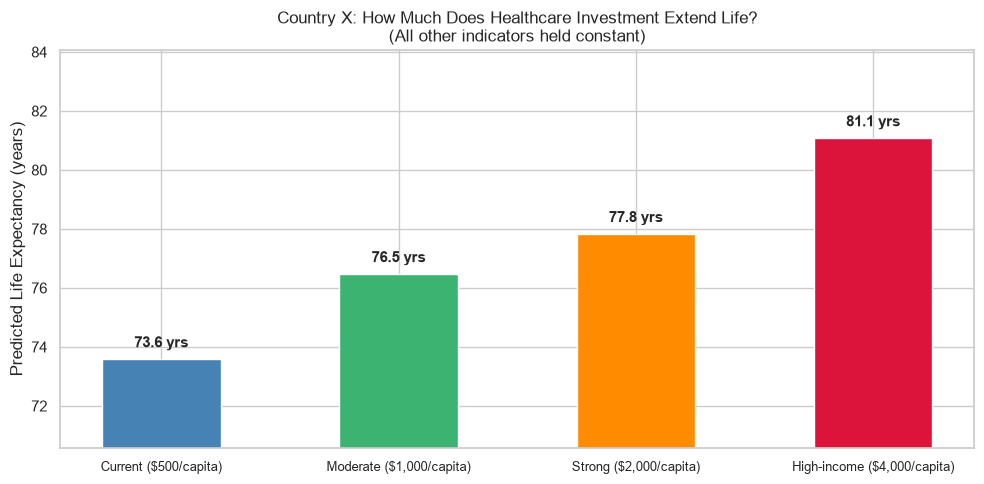

In [27]:
colors = ['steelblue', 'mediumseagreen', 'darkorange', 'crimson']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(what_if_preds.keys(), what_if_preds.values(), color=colors, width=0.5)

# Set y-axis range with a little padding so labels fit
y_min = min(what_if_preds.values()) - 3
y_max = max(what_if_preds.values()) + 3
ax.set_ylim(y_min, y_max)

# Label each bar with the predicted value
for bar, pred in zip(bars, what_if_preds.values()):
    ax.text(bar.get_x() + bar.get_width() / 2, pred + 0.3,
            f'{pred:.1f} yrs', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

ax.set_ylabel('Predicted Life Expectancy (years)')
ax.set_title('Country X: How Much Does Healthcare Investment Extend Life?\n'
             '(All other indicators held constant)')
ax.tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.show()

---
## 9 · Summary of Findings



In [28]:
# --- Section 9: Summary of Findings ---

print('=' * 60)
print('SUMMARY OF FINDINGS')
print('=' * 60)

# Q1
top_country     = top20.index[0]
top_growth      = top20['growth_pct'].iloc[0]
top_gdp_2000    = top20['gdp_2000'].iloc[0]
top_gdp_2022    = top20['gdp_2022'].iloc[0]
print(f'\nQ1 — Fastest-growing economy (2000–2022):')
print(f'     {top_country}: +{top_growth:.0f}%')
print(f'     GDP per capita PPP: ${top_gdp_2000:,.0f} → ${top_gdp_2022:,.0f}')

# Q2
top_corr_country = country_corr.index[0]
top_corr_value   = country_corr.iloc[0]
print(f'\nQ2 — Investment vs. growth:')
print(f'     Overall correlation: {corr:.3f}')
print(f'     Strongest link: {top_corr_country} (r = {top_corr_value:.3f})')

# Q3
top_livable         = top20_q3.index[0]
top_livable_score   = top20_q3['livability_index'].iloc[0]
bot_livable         = bot20_q3.index[0]
bot_livable_score   = bot20_q3['livability_index'].iloc[0]
countries_in_q3     = len(q3)
print(f'\nQ3 — Livability index ({countries_in_q3} countries with complete data):')
print(f'     Best:  {top_livable} (score {top_livable_score:.3f})')
print(f'     Worst: {bot_livable} (score {bot_livable_score:.3f})')

# Q4
gdp_2009 = q4.loc[q4['year'] == 2009, 'avg_growth'].values[0]
gdp_2020 = q4.loc[q4['year'] == 2020, 'avg_growth'].values[0]
gdp_2021 = q4.loc[q4['year'] == 2021, 'avg_growth'].values[0]
print(f'\nQ4 — Crisis impact (world average GDP growth):')
print(f'     2009 (financial crisis): {gdp_2009:.2f}%')
print(f'     2020 (COVID-19):         {gdp_2020:.2f}%')
print(f'     2021 (recovery):         {gdp_2021:.2f}%')

# Q5
print(f'\nQ5 — Life expectancy prediction model:')
print(f'     Linear Regression:  R2 = {lr_r2:.3f}, MAE = {lr_mae:.2f} years')
print(f'     Random Forest:      R2 = {rf_r2:.3f}, MAE = {rf_mae:.2f} years')

# Section 8
baseline     = list(what_if_preds.values())[0]
high_spend   = list(what_if_preds.values())[-1]
gain         = high_spend - baseline
print(f'\nSection 8 — Prediction scenario (Country X):')
print(f'     Baseline life expectancy:      {baseline:.1f} years')
print(f'     At high-income health spend:   {high_spend:.1f} years (+{gain:.1f} years)')

print('\n' + '=' * 60)

SUMMARY OF FINDINGS

Q1 — Fastest-growing economy (2000–2022):
     China: +429%
     GDP per capita PPP: $4,066 → $21,499

Q2 — Investment vs. growth:
     Overall correlation: 0.189
     Strongest link: Mongolia (r = 0.760)

Q3 — Livability index (165 countries with complete data):
     Best:  Ireland (score 0.904)
     Worst: Namibia (score 0.169)

Q4 — Crisis impact (world average GDP growth):
     2009 (financial crisis): -0.28%
     2020 (COVID-19):         -5.28%
     2021 (recovery):         5.73%

Q5 — Life expectancy prediction model:
     Linear Regression:  R2 = 0.600, MAE = 4.09 years
     Random Forest:      R2 = 0.922, MAE = 1.46 years

Section 8 — Prediction scenario (Country X):
     Baseline life expectancy:      73.6 years
     At high-income health spend:   81.1 years (+7.5 years)



## 9 · Summary of Findings

| Question | Key Finding |
|---|---|
| Q1: Fastest-growing economy | China grew GDP per capita (PPP) by +429% since 2000: from $4,066 to $21,499 |
| Q2: Investment vs. growth | Weak positive correlation globally (r = 0.189); strongest in Mongolia (r = 0.760) |
| Q3: Best livability | Ireland scores highest (0.904) on income + life expectancy + equality; 165 countries compared |
| Q4: Crisis impact | COVID-19 caused a deeper contraction than 2008: world avg GDP growth fell 8 pp (to -5.3%) vs 4 pp (to -0.3%) in the financial crisis |
| Q5: Life expectancy model | Random Forest R2 = 0.922, MAE = 1.46 years; health expenditure is the #1 predictor |
| Scenario | Country X: healthcare spending from $500 to $4,000/capita predicts +7.5 years of life expectancy |
